## 0. Setup — and the rules that prevent data leakage

| Risk | What we do about it |
|---|---|
| The same person in training and evaluation | Strict **subject-wise** split; `assert` that subject sets are disjoint |
| Scaler sees validation/test data | `StandardScaler` fitted on **meta-train subjects only**; the class prior also comes from meta-train subjects only |
| Query epochs that are near-duplicates of support epochs | **Temporal guard**: queries within 5 epochs of any support epoch are excluded |
| Smoothing lets a support label "vote" for its neighbours | Support epochs are **excluded from the averaging** |
| Choosing checkpoint, β or smoothing window on the test subjects | All choices are made on the **5 meta-validation subjects**; the 7 test subjects are first used in section 8 |
| Frozen dataset modified | Read-only access + **SHA-256** fingerprint checked at start and end |

Data path (same as `project1.ipynb`): `MyDrive/Colab Notebooks/ColabData/frozen/`. If the files are not found there, you'll be asked to upload them.

In [27]:
# ---- Imports & Colab setup -------------------------------------------------
import os, sys, json, copy, time, random, hashlib, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=UserWarning)

IN_COLAB = "google.colab" in sys.modules
DRIVE_ROOT = Path("/content/drive/MyDrive/Colab Notebooks/ColabData")

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    FROZEN_DIR = DRIVE_ROOT / "frozen"             # READ-ONLY: never written to
    OUT_DIR    = DRIVE_ROOT / "oneshot_outputs"            # all our outputs go here instead
else:
    FROZEN_DIR = Path("frozen")                    # local fallback (not Colab)
    OUT_DIR    = Path("oneshot_outputs")

REQUIRED = ["train_final.parquet", "test_final.parquet", "feature_cols_final.json"]

# If the frozen files are not on Drive, let the user upload them manually.
if not all((FROZEN_DIR / f).exists() for f in REQUIRED):
    if IN_COLAB:
        from google.colab import files
        print("Frozen files not found on Drive -> please upload:", REQUIRED)
        uploaded = files.upload()
        FROZEN_DIR = Path("/content/frozen_uploaded")
        FROZEN_DIR.mkdir(exist_ok=True)
        for name, content in uploaded.items():
            (FROZEN_DIR / name).write_bytes(content)
    missing = [f for f in REQUIRED if not (FROZEN_DIR / f).exists()]
    assert not missing, f"Missing frozen files: {missing}"

OUT_DIR.mkdir(parents=True, exist_ok=True)

# Fingerprint the frozen files NOW; we re-check at the very end of the notebook.
def sha256(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for block in iter(lambda: fh.read(chunk), b""):
            h.update(block)
    return h.hexdigest()

FROZEN_HASHES = {f: sha256(FROZEN_DIR / f) for f in REQUIRED}
print("Frozen data folder :", FROZEN_DIR)
print("Outputs folder     :", OUT_DIR)
for f, h in FROZEN_HASHES.items():
    print(f"  {f:28s} sha256 = {h[:16]}...")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Frozen data folder : /content/drive/MyDrive/Colab Notebooks/ColabData/frozen
Outputs folder     : /content/drive/MyDrive/Colab Notebooks/ColabData/oneshot_outputs
  train_final.parquet          sha256 = 92df5884e56c6142...
  test_final.parquet           sha256 = 1d0ce78ec4e29a8b...
  feature_cols_final.json      sha256 = 9f512eb9baa59024...


In [28]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import f1_score

def set_seed(seed: int):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

SEED = 42
set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| device:", device)

PyTorch: 2.11.0+cu130 | device: cuda


## 1. Load the frozen data (read-only)

`train_final.parquet` (24 subjects), `test_final.parquet` (7 different subjects) and the 12 agreed features. They come from `project1.ipynb`: raw movement, 5-epoch rolling heart-rate/movement statistics, epoch-to-epoch deltas, per-subject z-scores, step bursts and night position.

In [29]:
train_df = pd.read_parquet(FROZEN_DIR / "train_final.parquet")
test_df  = pd.read_parquet(FROZEN_DIR / "test_final.parquet")
with open(FROZEN_DIR / "feature_cols_final.json") as fh:
    feature_cols = json.load(fh)

print("train_final:", train_df.shape, "| subjects:", train_df["subject"].nunique())
print("test_final :", test_df.shape,  "| subjects:", test_df["subject"].nunique())
print(f"\n{len(feature_cols)} frozen features:")
for c in feature_cols:
    print("  -", c)

# ---- sanity checks on the frozen data -------------------------------------
assert len(feature_cols) == 12
assert set(feature_cols) <= set(train_df.columns) and set(feature_cols) <= set(test_df.columns)
assert np.isfinite(train_df[feature_cols].to_numpy()).all(), "NaN/inf in train features"
assert np.isfinite(test_df[feature_cols].to_numpy()).all(),  "NaN/inf in test features"
overlap = set(train_df["subject"]) & set(test_df["subject"])
assert not overlap, f"Subjects present in both train and test: {overlap}"
print("\nOK: features finite, and train/test subjects are disjoint.")

train_final: (19501, 24) | subjects: 24
test_final : (6007, 24) | subjects: 7

12 frozen features:
  - acc_mean
  - acc_std
  - hr_mean_clipped_roll5_mean
  - hr_mean_clipped_roll5_std
  - acc_mean_roll5_mean
  - acc_mean_roll5_std
  - hr_delta
  - acc_delta
  - hr_mean_clipped_subj_z
  - acc_mean_subj_z
  - steps_roll5_sum
  - night_position

OK: features finite, and train/test subjects are disjoint.


In [30]:
# The raw `stage` column has 6 codes because stage 3 and 4 are BOTH "N3" -> use the merged text label.
LABELS = ["Wake", "N1", "N2", "N3", "REM"]
N_CLASSES = len(LABELS)
label_to_id = {n: i for i, n in enumerate(LABELS)}

train_df = train_df.assign(label=train_df["stage_label"].map(label_to_id))   # new DataFrames; files untouched
test_df  = test_df.assign(label=test_df["stage_label"].map(label_to_id))
assert train_df["label"].notna().all() and test_df["label"].notna().all()

# (test labels are only mapped here; they are not inspected until section 8)
print("Epochs per subject and stage - TRAINING subjects (first 8 shown):")
train_df.groupby(["subject", "stage_label"]).size().unstack(fill_value=0)[LABELS].head(8)

Epochs per subject and stage - TRAINING subjects (first 8 shown):


stage_label,Wake,N1,N2,N3,REM
subject,,,,,
1066528,139,79,270,60,270
1360686,94,33,427,163,208
1449548,102,35,479,72,198
1455390,84,57,633,0,180
1818471,10,51,535,142,220
2598705,17,37,427,152,218
2638030,123,42,491,126,166
3509524,53,23,248,45,48


**Observation.** Some *training* subjects lack a stage entirely (3 of 24 have only 4 stages) — the episode sampler below handles that automatically by building 4-way episodes for those people. Whether a subject has enough epochs of every stage for K = 10 shots is checked by the sampler as well (a stage is used only if it has at least K + 1 epochs).

## 2. Subject-based split

In few-shot learning there are two levels of "unseen":

* **Meta-train subjects** — people whose data the embedding is trained on (via simulated episodes).
* **Meta-validation subjects** — held out to choose the best checkpoint.
* **Meta-test subjects** — completely new people; the *support* epochs and the *query* epochs both come from the same new person, and the model has never seen them.

We use the same split as the contrastive notebook (`GroupShuffleSplit`, seed 42, 80/20 on the 24 training subjects), so both parts of the project are comparable.

In [31]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
tr_idx, va_idx = next(gss.split(train_df, groups=train_df["subject"]))

fit_df  = train_df.iloc[tr_idx].reset_index(drop=True)    # meta-train
val_df  = train_df.iloc[va_idx].reset_index(drop=True)    # meta-validation
test_df = test_df.reset_index(drop=True)                  # meta-test

S_fit, S_val, S_test = (set(d["subject"]) for d in (fit_df, val_df, test_df))
assert not (S_fit & S_val) and not (S_fit & S_test) and not (S_val & S_test), "Subject leakage!"
print(f"meta-train: {len(S_fit)} subjects | meta-val: {len(S_val)} subjects {sorted(S_val)} | meta-test: {len(S_test)} subjects")

meta-train: 19 subjects | meta-val: 5 subjects ['1066528', '4314139', '5132496', '781756', '8173033'] | meta-test: 7 subjects


## 3. Scaling and per-subject data structures

Re-fit a `StandardScaler` on the **meta-train subjects only** (the frozen features were standardised using all 24 training subjects, which includes our validation people — re-fitting is the strict way to keep them out). Then store each subject's data separately, sorted by time, because **episodes are built inside one subject**:

```
subject_data[s] = { X: features [n_epochs, 12],  y: stage ids,  t: epoch start times (s),  by_class: {stage: indices} }
```

In [32]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(fit_df[feature_cols].to_numpy())      # fit ONLY on meta-train subjects

def build_subject_data(df):
    X = scaler.transform(df[feature_cols].to_numpy()).astype(np.float32)
    y = df["label"].to_numpy().astype(np.int64)
    t = df["time"].to_numpy().astype(np.float64)
    out = {}
    for s, idx in df.groupby("subject").indices.items():
        idx = np.asarray(idx)
        idx = idx[np.argsort(t[idx], kind="stable")]                  # chronological order
        yy = y[idx]
        out[s] = {"X": X[idx], "y": yy, "t": t[idx],
                  "by_class": {c: np.where(yy == c)[0] for c in range(N_CLASSES)}}
    return out

train_data, val_data, test_data = build_subject_data(fit_df), build_subject_data(val_df), build_subject_data(test_df)
print("meta-train subjects:", len(train_data), "| meta-val:", len(val_data), "| meta-test:", len(test_data))
s0 = next(iter(train_data)); print("example subject", s0, {k: (v.shape if hasattr(v, "shape") else "dict") for k, v in train_data[s0].items()})

meta-train subjects: 19 | meta-val: 5 | meta-test: 7
example subject 1360686 {'X': (925, 12), 'y': (925,), 't': (925,), 'by_class': 'dict'}


## 4. Episodes — and a leak that is easy to miss

An **episode** simulates one-shot learning for one person:

1. Pick a subject.
2. **Support set:** K random epochs of each stage (the "labelled examples").
3. **Query set:** other epochs of the same subject — the model must classify them using only the support set.

### ⚠️ The temporal-neighbour leak
Our features contain **5-epoch rolling statistics** and epoch-to-epoch deltas, so epoch *t* and epoch *t+1* are *almost the same feature vector*. If a query epoch sits right next to a support epoch of the same stage, "nearest prototype" works by simply recognising the neighbour — not by understanding sleep. That would make one-shot accuracy look far better than it is.

**Fix: temporal guard.** Any query epoch within **5 epochs (150 s)** of *any* support epoch is excluded. Five epochs equals the rolling-window length, so no query shares rolling-window data with a support epoch. In section 9 we measure how much the score would be inflated *without* the guard.

Ordering convention (important for the maths later): support epochs are stored **class-major** — all K shots of class 1, then all K shots of class 2, … — so reshaping to `[n_classes, K, dim]` and averaging over K gives the prototypes.

In [33]:
GUARD_EPOCHS = 5
GUARD_SEC = GUARD_EPOCHS * 30.0        # each epoch is 30 s

def sample_episode(d, k, n_query, rng, guard_sec=GUARD_SEC):
    """Build one episode from one subject's data `d`.
    k        : shots per class in the support set
    n_query  : max queries per class (None = use ALL allowed queries; used at test time)
    Returns dict(classes, sup, sup_y, q, q_y) with indices into d["X"], or None if impossible."""
    # a class is usable only if it has k support epochs AND at least one more epoch to query
    classes = [c for c in range(N_CLASSES) if len(d["by_class"][c]) >= k + 1]
    if len(classes) < 2:
        return None
    sup = np.concatenate([rng.choice(d["by_class"][c], size=k, replace=False) for c in classes])  # class-major
    sup_y = np.repeat(classes, k)

    # temporal guard: distance (in seconds) from each epoch to its closest support epoch
    dist = np.abs(d["t"][:, None] - d["t"][sup][None, :]).min(axis=1)
    allowed = dist > guard_sec                       # also excludes the support epochs themselves (dist = 0)

    q_idx, q_y = [], []
    for c in classes:
        pool = d["by_class"][c]
        pool = pool[allowed[pool]]
        if len(pool) == 0:
            continue
        if n_query is not None and len(pool) > n_query:
            pool = rng.choice(pool, size=n_query, replace=False)
        q_idx.append(pool); q_y.append(np.full(len(pool), c))
    if not q_idx:
        return None
    return {"classes": classes, "sup": sup, "sup_y": sup_y,
            "q": np.concatenate(q_idx), "q_y": np.concatenate(q_y)}

# ---- look at one episode and verify the guard works ----
rng_demo = np.random.default_rng(0)
s_demo = sorted(test_data)[0]
ep = sample_episode(test_data[s_demo], k=1, n_query=None, rng=rng_demo)
d = test_data[s_demo]
print(f"Subject {s_demo}: one-shot episode, classes = {[LABELS[c] for c in ep['classes']]}")
print("Support epochs (stage @ minute):", [(LABELS[y], round(d['t'][i] / 60, 1)) for i, y in zip(ep["sup"], ep["sup_y"])])
print("Number of query epochs:", len(ep["q"]), "of", len(d["y"]), "epochs in the night")
gap = np.abs(d["t"][ep["q"]][:, None] - d["t"][ep["sup"]][None, :]).min()
print(f"Closest query-to-support gap: {gap:.0f} s  (must be > {GUARD_SEC:.0f} s)")
assert gap > GUARD_SEC and not set(ep["q"]) & set(ep["sup"])

Subject 3997827: one-shot episode, classes = ['Wake', 'N1', 'N2', 'N3', 'REM']
Support epochs (stage @ minute): [('Wake', np.float64(248.0)), ('N1', np.float64(300.0)), ('N2', np.float64(265.5)), ('N3', np.float64(56.5)), ('REM', np.float64(237.5))]
Number of query epochs: 903 of 958 epochs in the night
Closest query-to-support gap: 180 s  (must be > 150 s)


## 5. Prototypical network and loss

**Embedding network** `f(x)`: a small MLP, 12 → 64 → 64 → 32. It maps an epoch to a 32-d embedding.

**Prototype** of stage *c* in an episode = mean of the support embeddings of that stage:
$$\mathbf{p}_c = \frac{1}{K}\sum_{x\in S_c} f(x)$$

**Classification of a query** $x$: softmax over *negative squared Euclidean distances* to the prototypes
$$P(y=c\mid x)=\frac{\exp(-\lVert f(x)-\mathbf{p}_c\rVert^2)}{\sum_{c'}\exp(-\lVert f(x)-\mathbf{p}_{c'}\rVert^2)}$$

**Loss** = cross-entropy of that distribution on the query epochs. Gradients flow through both the queries *and* the prototypes, so the network is trained to make "average of K examples" a good class summary.

Why this fits one-shot learning: at test time the *network is never retrained* — we only compute new prototypes from the K labelled epochs of the new person.

*No BatchNorm* is used on purpose: an episode has few samples and BatchNorm statistics would behave differently at train and test time.

In [34]:
EMB_DIM = 32

class ProtoEncoder(nn.Module):
    def __init__(self, in_dim, hidden=64, out_dim=EMB_DIM):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(in_dim, hidden), nn.ReLU(),
                                 nn.Linear(hidden, hidden), nn.ReLU(),
                                 nn.Linear(hidden, out_dim))
    def forward(self, x):
        return self.net(x)

def episode_loss(model, X_t, ep, k):
    """Prototypical loss for one episode. X_t = the subject's features as a tensor on `device`."""
    zs = model(X_t[torch.as_tensor(ep["sup"], device=device)])          # [n_cls*k, D]  (class-major)
    zq = model(X_t[torch.as_tensor(ep["q"],   device=device)])          # [n_query, D]
    protos = zs.reshape(len(ep["classes"]), k, -1).mean(dim=1)          # [n_cls, D]
    pos = {c: i for i, c in enumerate(ep["classes"]) }
    q_pos = torch.as_tensor([pos[c] for c in ep["q_y"]], device=device) # query labels -> index within the episode
    sq_dist = ((zq[:, None, :] - protos[None, :, :]) ** 2).sum(-1)      # [n_query, n_cls]
    logits = -sq_dist
    loss = F.cross_entropy(logits, q_pos)
    acc = (logits.argmax(1) == q_pos).float().mean().item()
    return loss, acc

model = ProtoEncoder(len(feature_cols)).to(device)
untrained_model = copy.deepcopy(model)                       # random-weights reference for the evaluation
print(model, "\nParameters:", sum(p.numel() for p in model.parameters()))

ProtoEncoder(
  (net): Sequential(
    (0): Linear(in_features=12, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=32, bias=True)
  )
) 
Parameters: 7072


## 6. Episodic training

Each optimisation step averages the loss over a few episodes. For every episode we

* choose a **random meta-train subject**,
* choose K from {1, 3, 5} (mostly small, so the network is good at one-shot but not brittle),
* take up to **15 query epochs per stage** — equal numbers per stage, so the **class imbalance is handled by the sampling itself** (N2 does not dominate).

Every 100 steps we measure **one-shot macro-F1 on the meta-validation subjects** (fixed random seeds, so numbers are comparable between checkpoints) and keep the best weights.

*Macro-F1* averages the F1 of the five stages, so rare stages (N1) count as much as N2. Chance level for 5 balanced classes is about 0.2.

In [35]:
from scipy.ndimage import uniform_filter1d

class_prior = np.bincount(fit_df["label"].to_numpy(), minlength=N_CLASSES) / len(fit_df)   # stage frequencies of the META-TRAIN subjects only
log_prior = np.log(class_prior)

@torch.no_grad()
def embed_all(m, data):
    m.eval()
    return {s: m(torch.from_numpy(d["X"]).to(device)).cpu().numpy() for s, d in data.items()}

def conf_metrics(cm):
    # metrics from a confusion matrix (rows = true stage). Macro-F1 and balanced accuracy average over the stages present in the truth.
    tp = np.diag(cm).astype(float)
    support, predicted = cm.sum(1), cm.sum(0)
    rec, prec = tp / np.maximum(support, 1), tp / np.maximum(predicted, 1)
    f1 = np.where(prec + rec > 0, 2 * prec * rec / np.maximum(prec + rec, 1e-12), 0.0)
    present = support > 0
    return {"accuracy": tp.sum() / cm.sum(), "balanced_acc": rec[present].mean(), "macro_f1": f1[present].mean(),
            "precision": prec, "recall": rec, "f1": f1}

def smooth_masked(P, valid, win):
    # moving average of class probabilities over `win` epochs; epochs with valid = 0 (the support epochs) contribute nothing
    if win <= 1:
        return P
    num = uniform_filter1d(P * valid[:, None], size=win, axis=0, mode="constant")
    den = uniform_filter1d(valid.astype(float), size=win, mode="constant")[:, None]
    return num / np.clip(den, 1e-9, None)

def evaluate_grid(data, models, ks, n_episodes, configs, guard_sec, seed, with_baselines=False):
    # For every subject and K draw `n_episodes` random episodes; score every (model, beta, window) on the SAME episodes.
    #   configs = list of (beta, win): beta = strength of the class-prior term, win = smoothing window (1 = none).
    #   (0, 1) is the pure nearest-prototype rule of the original ProtoNet.
    # Returns (per-episode DataFrame, pooled confusion matrices keyed by (method, beta, win, k)).
    embs = {name: embed_all(m, data) for name, m in models.items()}
    rows, conf = [], {}

    def record(method, beta, win, k, s, e, q_y, pred):
        cm = np.bincount(q_y * N_CLASSES + pred, minlength=N_CLASSES ** 2).reshape(N_CLASSES, N_CLASSES)
        conf[(method, beta, win, k)] = conf.get((method, beta, win, k), 0) + cm
        mt = conf_metrics(cm)
        rows.append({"method": method, "beta": beta, "win": win, "k": k, "subject": s, "episode": e,
                     "accuracy": mt["accuracy"], "balanced_acc": mt["balanced_acc"], "macro_f1": mt["macro_f1"]})

    for k in ks:
        for si, (s, d) in enumerate(data.items()):
            rng = np.random.default_rng([seed, k, si])
            rng_rand = np.random.default_rng([seed, k, si, 999])
            for e in range(n_episodes):
                ep = sample_episode(d, k, None, rng, guard_sec)
                if ep is None:
                    continue
                classes = np.asarray(ep["classes"])
                valid = np.ones(len(d["y"])); valid[ep["sup"]] = 0.0              # support epochs never vote
                for name, E_all in embs.items():
                    E = E_all[s]
                    protos = E[ep["sup"]].reshape(len(classes), k, -1).mean(axis=1)
                    d2 = ((E[:, None, :] - protos[None, :, :]) ** 2).sum(-1)       # distance of every epoch of this night to each prototype
                    for beta, win in configs:
                        z = -d2 + beta * log_prior[classes][None, :]
                        z = z - z.max(axis=1, keepdims=True)
                        P = np.exp(z); P /= P.sum(axis=1, keepdims=True)
                        pred = classes[smooth_masked(P, valid, win)[ep["q"]].argmax(axis=1)]
                        record(name, beta, win, k, s, e, ep["q_y"], pred)
                if with_baselines:
                    X = d["X"]
                    protos = X[ep["sup"]].reshape(len(classes), k, -1).mean(axis=1)
                    pred = classes[((X[ep["q"]][:, None, :] - protos[None]) ** 2).sum(-1).argmin(axis=1)]
                    record("raw features (no learning)", 0.0, 1, k, s, e, ep["q_y"], pred)
                    record("random guess", 0.0, 1, k, s, e, ep["q_y"], rng_rand.choice(classes, size=len(ep["q"])))
    return pd.DataFrame(rows), conf

def subject_level(df):
    # average episodes inside each subject first; the subject is the unit we want to generalise to
    return df.groupby(["method", "beta", "win", "k", "subject"])[["accuracy", "balanced_acc", "macro_f1"]].mean().reset_index()

step  100 | train loss 1.410 | train episode acc 0.450 | val 1-shot macro-F1 0.313  *best*
step  200 | train loss 1.265 | train episode acc 0.474 | val 1-shot macro-F1 0.336  *best*
step  300 | train loss 1.198 | train episode acc 0.510 | val 1-shot macro-F1 0.341  *best*
step  400 | train loss 1.180 | train episode acc 0.514 | val 1-shot macro-F1 0.347  *best*
step  500 | train loss 1.155 | train episode acc 0.515 | val 1-shot macro-F1 0.353  *best*
step  600 | train loss 1.123 | train episode acc 0.536 | val 1-shot macro-F1 0.355  *best*
step  700 | train loss 1.090 | train episode acc 0.547 | val 1-shot macro-F1 0.351
step  800 | train loss 1.072 | train episode acc 0.546 | val 1-shot macro-F1 0.349
step  900 | train loss 1.081 | train episode acc 0.549 | val 1-shot macro-F1 0.352
step 1000 | train loss 1.068 | train episode acc 0.562 | val 1-shot macro-F1 0.347
step 1100 | train loss 1.020 | train episode acc 0.579 | val 1-shot macro-F1 0.346
step 1200 | train loss 1.021 | train ep

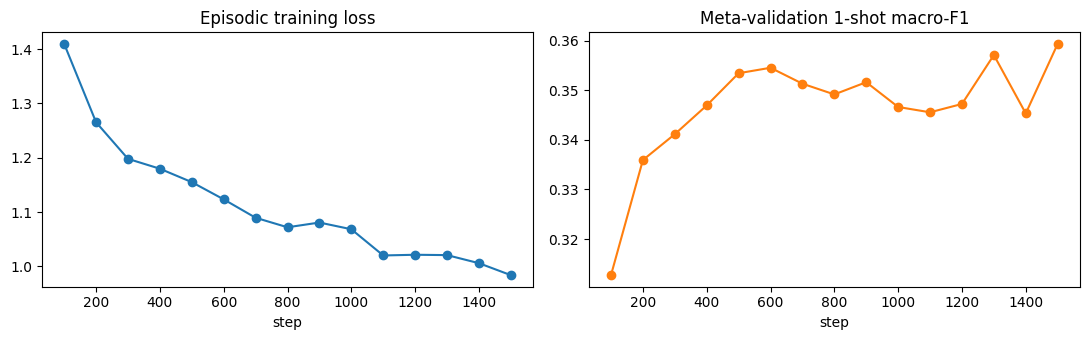

In [36]:
N_STEPS          = 1500
EPISODES_PER_STEP = 4
TRAIN_K_CHOICES  = [1, 3, 5]
N_QUERY          = 15
LR               = 1e-3
VAL_EVERY        = 100

train_subjects = sorted(train_data)
train_X = {s: torch.from_numpy(train_data[s]["X"]).to(device) for s in train_subjects}
opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=1e-4)
rng_train = np.random.default_rng(SEED)

def quick_val_f1(m):
    df, _ = evaluate_grid(val_data, {"m": m}, [1], 20, [(0.0, 1)], GUARD_SEC, seed=123)       # pure rule, validation subjects
    return df.groupby("subject")["macro_f1"].mean().mean()

history = {"step": [], "train_loss": [], "train_acc": [], "val_step": [], "val_f1_1shot": []}
best = {"f1": -1, "state": None, "step": 0}
run_loss, run_acc = [], []
t0 = time.time()

for step in range(1, N_STEPS + 1):
    model.train()
    losses = []
    for _ in range(EPISODES_PER_STEP):
        s = train_subjects[rng_train.integers(len(train_subjects))]
        k = int(rng_train.choice(TRAIN_K_CHOICES))
        ep = sample_episode(train_data[s], k, N_QUERY, rng_train, GUARD_SEC)
        if ep is None:
            continue
        l, a = episode_loss(model, train_X[s], ep, k)
        losses.append(l); run_acc.append(a)
    loss = torch.stack(losses).mean()
    opt.zero_grad(); loss.backward(); opt.step()
    run_loss.append(loss.item())

    if step % VAL_EVERY == 0:
        v = quick_val_f1(model)
        history["step"].append(step); history["train_loss"].append(float(np.mean(run_loss)))
        history["train_acc"].append(float(np.mean(run_acc))); history["val_step"].append(step); history["val_f1_1shot"].append(v)
        run_loss, run_acc = [], []
        if v > best["f1"]:
            best = {"f1": v, "state": copy.deepcopy(model.state_dict()), "step": step}
        print(f"step {step:4d} | train loss {history['train_loss'][-1]:.3f} | train episode acc {history['train_acc'][-1]:.3f} "
              f"| val 1-shot macro-F1 {v:.3f}{'  *best*' if best['step'] == step else ''}")

model.load_state_dict(best["state"])
print(f"\nBest checkpoint: step {best['step']} (val 1-shot macro-F1 {best['f1']:.3f}) | training time {time.time() - t0:.0f}s")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(history["step"], history["train_loss"], "o-"); ax[0].set(title="Episodic training loss", xlabel="step")
ax[1].plot(history["val_step"], history["val_f1_1shot"], "o-", color="C1"); ax[1].set(title="Meta-validation 1-shot macro-F1", xlabel="step")
plt.tight_layout(); plt.show()

## 7. Validation-only experiments (the 7 test subjects are still untouched)

Everything that involves a *choice* is done on the **5 meta-validation subjects**: how the model compares with simple baselines, whether the temporal guard matters, and — most importantly — **which class-prior strength β and smoothing window to use**.

### 7a. Reference comparison and guard ablation on the validation subjects

* *learned ProtoNet*, an *untrained* (random) encoder, nearest prototype on the *raw features*, and *random guessing* — all scored on the same episodes.
* The **temporal guard ablation**: the same trained model scored with the guard (queries ≥ 6 epochs away from any support epoch) and without it (only the support epochs themselves removed). The gap is the fake accuracy that near-duplicate neighbouring epochs would give.

In [37]:
KS = [1, 2, 5, 10]                               # shots per stage evaluated
N_EP_VAL = 50                                    # random episodes per subject and K on the validation subjects

res_a, _ = evaluate_grid(val_data, {"learned ProtoNet": model, "untrained encoder": untrained_model}, KS, N_EP_VAL, [(0.0, 1)], GUARD_SEC, seed=7, with_baselines=True)
sub_a = subject_level(res_a)
print("VALIDATION subjects - macro-F1 (mean over 5 subjects) per method and K  [pure nearest-prototype rule]:")
display(sub_a.groupby(["method", "k"])["macro_f1"].mean().unstack("k").round(3).loc[["learned ProtoNet", "untrained encoder", "raw features (no learning)", "random guess"]])

abl_guard, _ = evaluate_grid(val_data, {"learned ProtoNet": model}, [1, 5], N_EP_VAL, [(0.0, 1)], GUARD_SEC, seed=7)
abl_noguard, _ = evaluate_grid(val_data, {"learned ProtoNet": model}, [1, 5], N_EP_VAL, [(0.0, 1)], 0.0, seed=7)
ablation = pd.DataFrame({"with guard (our protocol)": subject_level(abl_guard).groupby("k")["macro_f1"].mean(),
                         "no guard (leaky)": subject_level(abl_noguard).groupby("k")["macro_f1"].mean()})
ablation["inflation"] = ablation["no guard (leaky)"] - ablation["with guard (our protocol)"]
print("\nTemporal-guard ablation (validation subjects, macro-F1):")
display(ablation.round(3))

VALIDATION subjects - macro-F1 (mean over 5 subjects) per method and K  [pure nearest-prototype rule]:


k,1,2,5,10
method,,,,
learned ProtoNet,0.353,0.387,0.426,0.432
untrained encoder,0.280,0.301,0.347,0.365
raw features (no learning),0.279,0.298,0.350,0.363
random guess,0.181,0.180,0.174,0.170



Temporal-guard ablation (validation subjects, macro-F1):


,with guard (our protocol),no guard (leaky),inflation
k,,,
1,0.353,0.377,0.024
5,0.426,0.472,0.046


### 7b. Choosing the class-prior strength β and the smoothing window — on the validation subjects only

The pure nearest-prototype rule treats all five stages as equally likely, but ~50 % of epochs are N2. Two post-processing steps can raise accuracy:

1. **Class prior** `β · log(prior)` added to the logits (the prior = stage frequencies of the *meta-train* subjects). β = 0 is the original rule.
2. **Temporal smoothing** of each epoch's probabilities over `win` neighbouring epochs of the same night, **excluding the support epochs** (their label is known; they must not "vote" for their neighbours). `win = 1` means no smoothing. It uses epochs before and after, so it is an offline step.

**Selection protocol (validation subjects only).** For every pair `(β, win)` in a grid we run the same 50 episodes per subject and K on the 5 validation subjects and compute, averaged over K ∈ {1, 2, 5, 10}:

* `objective = (accuracy + macro-F1) / 2`
* **constraint:** macro-F1 must not fall more than 0.005 below the pure ProtoNet's macro-F1. (A strong prior can buy accuracy by predicting "N2" for everything, which is not a better sleep scorer; this guard keeps the choice honest about macro-F1.)

The feasible pair with the highest objective is selected (ties → smaller β, then smaller window). If nothing beats the pure rule, the pure rule `(0, 1)` is kept. As a consistency check we also count in how many of the 5 validation subjects the selected setting beats the pure rule. Only the chosen pair is carried to the test evaluation.

In [38]:
BETAS = [0.0, 0.25, 0.5, 1.0, 1.5, 2.0]
WINS = [1, 5, 11, 21, 31]
GRID = [(b, w) for b in BETAS for w in WINS]
MF1_TOLERANCE = 0.005

val_grid, _ = evaluate_grid(val_data, {"ProtoNet": model}, KS, N_EP_VAL, GRID, GUARD_SEC, seed=7)
sub_val = subject_level(val_grid)

per_k = sub_val.groupby(["beta", "win", "k"])[["accuracy", "balanced_acc", "macro_f1"]].mean()          # mean over validation subjects
cfg_tab = per_k.groupby(["beta", "win"]).mean()                                                         # mean over K
cfg_tab["objective"] = 0.5 * (cfg_tab["accuracy"] + cfg_tab["macro_f1"])
pure = cfg_tab.loc[(0.0, 1)]
cfg_tab["feasible"] = cfg_tab["macro_f1"] >= pure["macro_f1"] - MF1_TOLERANCE

cand = cfg_tab[cfg_tab["feasible"]].reset_index().sort_values(["objective", "beta", "win"], ascending=[False, True, True])
SEL_BETA, SEL_WIN = float(cand.iloc[0]["beta"]), int(cand.iloc[0]["win"])

print("VALIDATION grid (means over 5 validation subjects and over K = 1, 2, 5, 10):")
print("accuracy:");     display(cfg_tab["accuracy"].unstack("win").round(3))
print("macro-F1:");     display(cfg_tab["macro_f1"].unstack("win").round(3))
print("objective = (accuracy + macro-F1)/2:"); display(cfg_tab["objective"].unstack("win").round(3))
print(f"\nPure ProtoNet on validation: accuracy {pure['accuracy']:.3f}, macro-F1 {pure['macro_f1']:.3f}  ->  macro-F1 must stay >= {pure['macro_f1'] - MF1_TOLERANCE:.3f}")
print(f"{int(cfg_tab['feasible'].sum())} of {len(cfg_tab)} settings satisfy the macro-F1 constraint.")
print(f"SELECTED on validation:  beta = {SEL_BETA},  smoothing window = {SEL_WIN} epochs")

# consistency across the validation subjects
obj_subj = sub_val.assign(obj=lambda d: 0.5 * (d["accuracy"] + d["macro_f1"])).groupby(["beta", "win", "subject"])["obj"].mean()
sel_vs_pure = (obj_subj.loc[(SEL_BETA, SEL_WIN)] - obj_subj.loc[(0.0, 1)])
print("\nPer-validation-subject change in objective, selected minus pure:", sel_vs_pure.round(3).to_dict())
print(f"Selected setting is better for {int((sel_vs_pure > 0).sum())} of {len(sel_vs_pure)} validation subjects.")

VALIDATION grid (means over 5 validation subjects and over K = 1, 2, 5, 10):
accuracy:


win,1,5,11,21,31
beta,,,,,
0.00,0.469,0.478,0.484,0.484,0.482
0.25,0.521,0.531,0.538,0.539,0.537
0.50,0.546,0.556,0.561,0.562,0.559
1.00,0.561,0.568,0.571,0.571,0.567
1.50,0.557,0.559,0.559,0.557,0.554
2.00,0.543,0.542,0.539,0.536,0.533


macro-F1:


win,1,5,11,21,31
beta,,,,,
0.00,0.399,0.401,0.400,0.394,0.389
0.25,0.407,0.403,0.397,0.390,0.386
0.50,0.389,0.380,0.374,0.369,0.364
1.00,0.345,0.336,0.333,0.330,0.323
1.50,0.307,0.298,0.295,0.289,0.282
2.00,0.266,0.258,0.252,0.243,0.236


objective = (accuracy + macro-F1)/2:


win,1,5,11,21,31
beta,,,,,
0.00,0.434,0.440,0.442,0.439,0.435
0.25,0.464,0.467,0.467,0.464,0.462
0.50,0.468,0.468,0.467,0.466,0.462
1.00,0.453,0.452,0.452,0.450,0.445
1.50,0.432,0.428,0.427,0.423,0.418
2.00,0.405,0.400,0.395,0.390,0.385



Pure ProtoNet on validation: accuracy 0.469, macro-F1 0.399  ->  macro-F1 must stay >= 0.394
6 of 30 settings satisfy the macro-F1 constraint.
SELECTED on validation:  beta = 0.25,  smoothing window = 11 epochs

Per-validation-subject change in objective, selected minus pure: {'1066528': 0.053, '4314139': 0.029, '5132496': 0.057, '781756': 0.01, '8173033': 0.017}
Selected setting is better for 5 of 5 validation subjects.


## 8. FINAL evaluation on the 7 held-out TEST subjects (run once)

From here on the **test subjects are used for the first and only time**. Nothing below changes any choice: the ProtoNet weights, the checkpoint, β and the smoothing window were all fixed on meta-train / meta-validation subjects.

We report, for every K ∈ {1, 2, 5, 10}, mean ± std **across the 7 test subjects** (each subject's score = mean over 100 random episodes) of **accuracy, balanced accuracy and macro-F1**, and then the **per-class precision and recall** of the **selected configuration** next to the **original ProtoNet** (`β = 0`, no smoothing). The two components are also shown separately so that you can see what each contributes.

In [39]:
N_EP_TEST = 100
final_cfgs = list(dict.fromkeys([(0.0, 1), (0.0, SEL_WIN), (SEL_BETA, 1), (SEL_BETA, SEL_WIN)]))
test_res, test_conf = evaluate_grid(test_data, {"ProtoNet": model}, KS, N_EP_TEST, final_cfgs, GUARD_SEC, seed=2024)
base_res, base_conf = evaluate_grid(test_data, {"untrained encoder": untrained_model}, KS, N_EP_TEST, [(0.0, 1)], GUARD_SEC, seed=2024, with_baselines=True)
all_res = pd.concat([test_res, base_res], ignore_index=True)
conf_all = {**test_conf, **base_conf}
sub_t = subject_level(all_res)

def label_of(r):
    if r["method"] != "ProtoNet":
        return r["method"]
    if (r["beta"], r["win"]) == (0.0, 1):                return "ProtoNet ORIGINAL (beta 0, no smoothing)"
    if (r["beta"], r["win"]) == (SEL_BETA, SEL_WIN):     return f"ProtoNet SELECTED (beta {SEL_BETA:g}, window {SEL_WIN})"
    return f"ProtoNet beta {r['beta']:g}, window {r['win']}"
sub_t["label"] = sub_t.apply(label_of, axis=1)
LBL_ORIG = "ProtoNet ORIGINAL (beta 0, no smoothing)"
LBL_SEL = f"ProtoNet SELECTED (beta {SEL_BETA:g}, window {SEL_WIN})"
print("Selected configuration (chosen on validation subjects):", LBL_SEL)

def fmt(g, col):
    return f"{g[col].mean():.3f} ± {g[col].std(ddof=1):.3f}"
rows = {}
for (lab, k), g in sub_t.groupby(["label", "k"]):
    rows[(lab, k)] = {"accuracy": fmt(g, "accuracy"), "balanced_acc": fmt(g, "balanced_acc"), "macro_f1": fmt(g, "macro_f1")}
summary = pd.DataFrame(rows).T
summary.index.names = ["method", "K"]
order = [LBL_ORIG, LBL_SEL] + [l for l in sub_t["label"].unique() if l.startswith("ProtoNet beta")] + ["untrained encoder", "raw features (no learning)", "random guess"]
order = list(dict.fromkeys(order))
print(f"\nTEST subjects (7 unseen people): mean ± std across subjects, 100 random episodes per subject and K")
display(summary.loc[[o for o in order if o in summary.index.get_level_values(0)]])

Selected configuration (chosen on validation subjects): ProtoNet SELECTED (beta 0.25, window 11)

TEST subjects (7 unseen people): mean ± std across subjects, 100 random episodes per subject and K


accuracy   balanced_acc  \
method                                   K                                  
ProtoNet ORIGINAL (beta 0, no smoothing) 1   0.383 ± 0.051  0.392 ± 0.053   
                                         2   0.427 ± 0.072  0.444 ± 0.058   
                                         5   0.470 ± 0.094  0.490 ± 0.064   
                                         10  0.494 ± 0.116  0.521 ± 0.068   
ProtoNet SELECTED (beta 0.25, window 11) 1   0.435 ± 0.054  0.384 ± 0.049   
                                         2   0.497 ± 0.078  0.429 ± 0.055   
                                         5   0.555 ± 0.101  0.459 ± 0.076   
                                         10  0.587 ± 0.112  0.469 ± 0.090   
ProtoNet beta 0, window 11               1   0.397 ± 0.056  0.395 ± 0.050   
                                         2   0.447 ± 0.082  0.446 ± 0.055   
                                         5   0.494 ± 0.107  0.483 ± 0.076   
                                         10  0.517 ± 0.131  0.500 ± 0.086   
ProtoNet beta 0.25, window 1             1   0.419 ± 0.050  0.385 ± 0.050   
                                         2   0.473 ± 0.067  0.434 ± 0.054   
                                         5   0.524 ± 0.089  0.475 ± 0.063   
                                         10  0.557 ± 0.099  0.501 ± 0.066   
untrained encoder                        1   0.353 ± 0.062  0.340 ± 0.043   
                                         2   0.384 ± 0.069  0.375 ± 0.055   
                                         5   0.429 ± 0.099  0.423 ± 0.063   
                                         10  0.456 ± 0.125  0.457 ± 0.061   
raw features (no learning)               1   0.361 ± 0.069  0.353 ± 0.045   
                                         2   0.382 ± 0.074  0.379 ± 0.057   
                                         5   0.423 ± 0.105  0.425 ± 0.064   
                                         10  0.450 ± 0.133  0.463 ± 0.068   
random guess                             1   0.200 ± 0.001  0.200 ± 0.001   
                                         2   0.200 ± 0.001  0.200 ± 0.003   
                                         5   0.200 ± 0.001  0.200 ± 0.003   
                                         10  0.200 ± 0.002  0.200 ± 0.003   

                                                  macro_f1  
method                                   K                  
ProtoNet ORIGINAL (beta 0, no smoothing) 1   0.329 ± 0.047  
                                         2   0.369 ± 0.060  
                                         5   0.397 ± 0.080  
                                         10  0.414 ± 0.105  
ProtoNet SELECTED (beta 0.25, window 11) 1   0.337 ± 0.048  
                                         2   0.382 ± 0.068  
                                         5   0.412 ± 0.094  
                                         10  0.427 ± 0.118  
ProtoNet beta 0, window 11               1   0.333 ± 0.050  
                                         2   0.377 ± 0.069  
                                         5   0.406 ± 0.097  
                                         10  0.420 ± 0.126  
ProtoNet beta 0.25, window 1             1   0.336 ± 0.046  
                                         2   0.379 ± 0.058  
                                         5   0.408 ± 0.079  
                                         10  0.429 ± 0.097  
untrained encoder                        1   0.284 ± 0.043  
                                         2   0.315 ± 0.055  
                                         5   0.349 ± 0.077  
                                         10  0.378 ± 0.100  
raw features (no learning)               1   0.291 ± 0.040  
                                         2   0.313 ± 0.049  
                                         5   0.345 ± 0.071  
                                         10  0.376 ± 0.105  
random guess                             1   0.170 ± 0.012  
                                         2   0.168 ± 0.014  
                               

### Per-class precision and recall, curves, confusion matrices, per-subject results and verdict


===== K = 1 shot(s) per stage - per-class precision / recall / F1 (pooled over test episodes) =====


ORIGINAL (beta 0, win 1)               SELECTED (beta 0.25, win 11)  \
                    precision recall     f1                    precision   
Wake                    0.230  0.312  0.265                        0.275   
N1                      0.108  0.276  0.156                        0.111   
N2                      0.588  0.319  0.413                        0.568   
N3                      0.386  0.540  0.451                        0.411   
REM                     0.409  0.455  0.430                        0.421   

                    
     recall     f1  
Wake  0.248  0.261  
N1    0.157  0.130  
N2    0.447  0.500  
N3    0.511  0.456  
REM   0.506  0.459


===== K = 2 shot(s) per stage - per-class precision / recall / F1 (pooled over test episodes) =====


ORIGINAL (beta 0, win 1)               SELECTED (beta 0.25, win 11)  \
                    precision recall     f1                    precision   
Wake                    0.257  0.378  0.306                        0.320   
N1                      0.125  0.326  0.181                        0.137   
N2                      0.647  0.339  0.445                        0.614   
N3                      0.434  0.615  0.509                        0.478   
REM                     0.455  0.514  0.483                        0.475   

                    
     recall     f1  
Wake  0.293  0.306  
N1    0.157  0.146  
N2    0.514  0.559  
N3    0.579  0.524  
REM   0.569  0.518


===== K = 5 shot(s) per stage - per-class precision / recall / F1 (pooled over test episodes) =====


ORIGINAL (beta 0, win 1)               SELECTED (beta 0.25, win 11)  \
                    precision recall     f1                    precision   
Wake                    0.266  0.425  0.327                        0.331   
N1                      0.137  0.352  0.197                        0.154   
N2                      0.707  0.378  0.493                        0.659   
N3                      0.453  0.635  0.529                        0.508   
REM                     0.476  0.589  0.527                        0.519   

                    
     recall     f1  
Wake  0.334  0.333  
N1    0.113  0.130  
N2    0.585  0.620  
N3    0.583  0.543  
REM   0.634  0.571


===== K = 10 shot(s) per stage - per-class precision / recall / F1 (pooled over test episodes) =====


ORIGINAL (beta 0, win 1)               SELECTED (beta 0.25, win 11)  \
                    precision recall     f1                    precision   
Wake                    0.233  0.447  0.306                        0.271   
N1                      0.141  0.368  0.204                        0.156   
N2                      0.770  0.402  0.528                        0.709   
N3                      0.415  0.649  0.506                        0.480   
REM                     0.493  0.649  0.561                        0.544   

                    
     recall     f1  
Wake  0.336  0.300  
N1    0.084  0.109  
N2    0.616  0.659  
N3    0.586  0.528  
REM   0.674  0.602

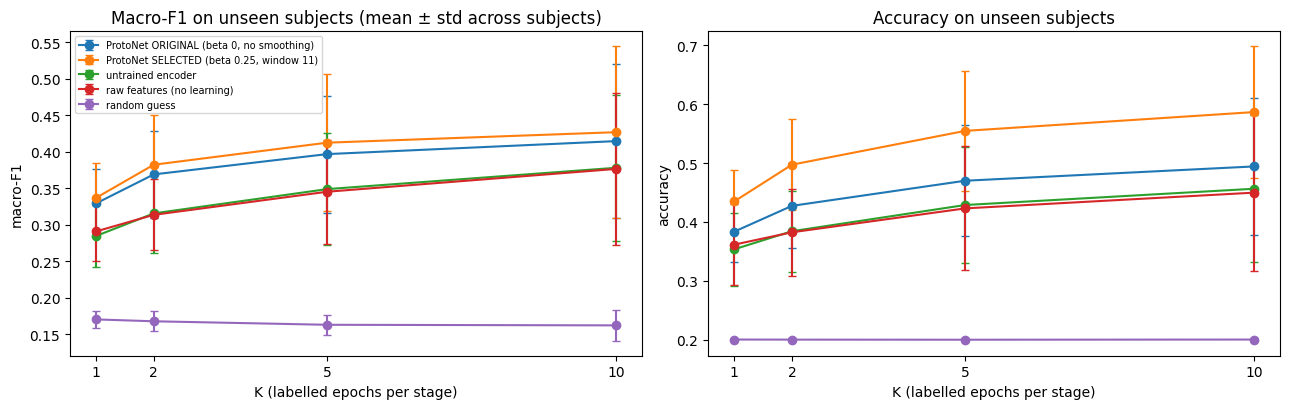

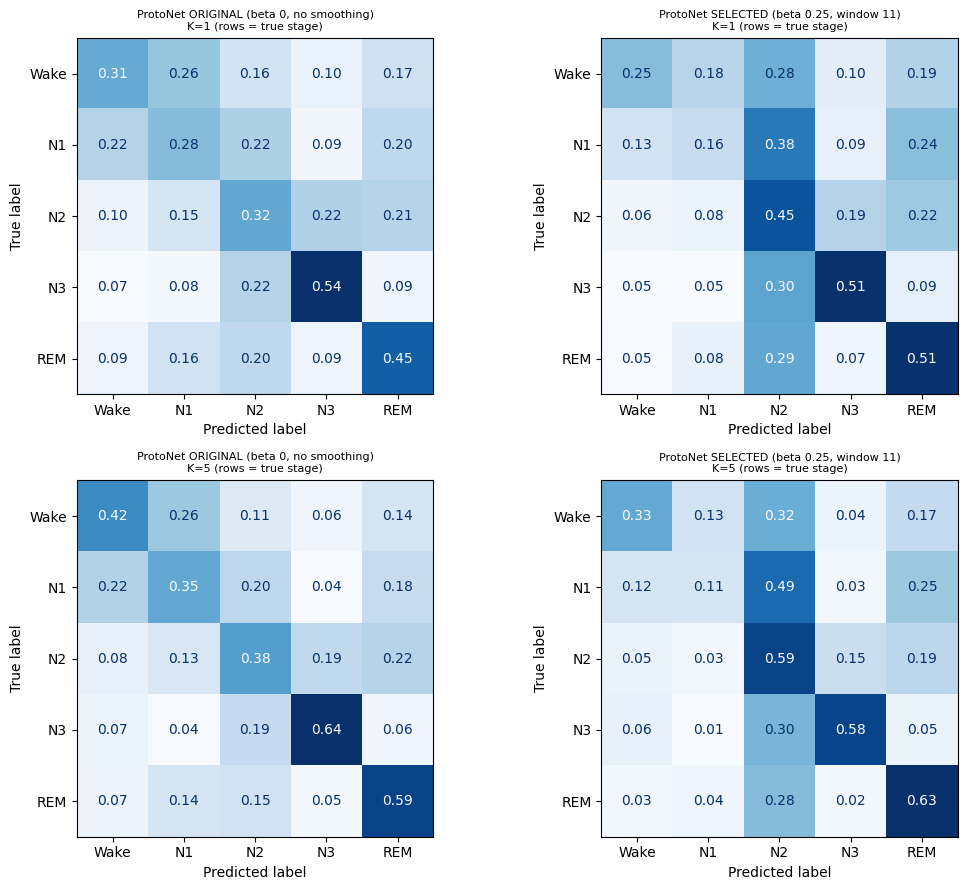


K = 1: per-subject macro-F1 / accuracy


macro-F1  \
label   ProtoNet ORIGINAL (beta 0, no smoothing)   
subject                                            
3997827                                    0.322   
4018081                                    0.329   
5498603                                    0.298   
6220552                                    0.278   
8258170                                    0.367   
8692923                                    0.297   
9618981                                    0.413   

                                                  \
label   ProtoNet SELECTED (beta 0.25, window 11)   
subject                                            
3997827                                    0.328   
4018081                                    0.348   
5498603                                    0.300   
6220552                                    0.283   
8258170                                    0.395   
8692923                                    0.298   
9618981                                    0.404   

                                        accuracy  \
label   ProtoNet ORIGINAL (beta 0, no smoothing)   
subject                                            
3997827                                    0.391   
4018081                                    0.446   
5498603                                    0.323   
6220552                                    0.329   
8258170                                    0.429   
8692923                                    0.343   
9618981                                    0.423   

                                                  
label   ProtoNet SELECTED (beta 0.25, window 11)  
subject                                           
3997827                                    0.448  
4018081                                    0.475  
5498603                                    0.363  
6220552                                    0.383  
8258170                                    0.516  
8692923                                    0.407  
9618981                                    0.452


K = 5: per-subject macro-F1 / accuracy


macro-F1  \
label   ProtoNet ORIGINAL (beta 0, no smoothing)   
subject                                            
3997827                                    0.354   
4018081                                    0.416   
5498603                                    0.330   
6220552                                    0.307   
8258170                                    0.498   
8692923                                    0.362   
9618981                                    0.508   

                                                  \
label   ProtoNet SELECTED (beta 0.25, window 11)   
subject                                            
3997827                                    0.336   
4018081                                    0.444   
5498603                                    0.352   
6220552                                    0.309   
8258170                                    0.566   
8692923                                    0.381   
9618981                                    0.498   

                                        accuracy  \
label   ProtoNet ORIGINAL (beta 0, no smoothing)   
subject                                            
3997827                                    0.460   
4018081                                    0.584   
5498603                                    0.364   
6220552                                    0.361   
8258170                                    0.588   
8692923                                    0.428   
9618981                                    0.505   

                                                  
label   ProtoNet SELECTED (beta 0.25, window 11)  
subject                                           
3997827                                    0.538  
4018081                                    0.633  
5498603                                    0.447  
6220552                                    0.449  
8258170                                    0.734  
8692923                                    0.532  
9618981                                    0.552


Verdict (selected vs original, paired over the 7 test subjects; an improvement is claimed only if the mean difference is > 0 in at least 5 of 7 subjects):
  K= 1 accuracy    : 0.383 -> 0.435  (Δ +0.051, better in 7/7 subjects)  => IMPROVEMENT
  K= 1 balanced_acc: 0.392 -> 0.384  (Δ -0.007, better in 2/7 subjects)  => WORSE
  K= 1 macro_f1    : 0.329 -> 0.337  (Δ +0.008, better in 6/7 subjects)  => IMPROVEMENT
  K= 2 accuracy    : 0.427 -> 0.497  (Δ +0.070, better in 7/7 subjects)  => IMPROVEMENT
  K= 2 balanced_acc: 0.444 -> 0.429  (Δ -0.015, better in 2/7 subjects)  => WORSE
  K= 2 macro_f1    : 0.369 -> 0.382  (Δ +0.013, better in 5/7 subjects)  => IMPROVEMENT
  K= 5 accuracy    : 0.470 -> 0.555  (Δ +0.085, better in 7/7 subjects)  => IMPROVEMENT
  K= 5 balanced_acc: 0.490 -> 0.459  (Δ -0.031, better in 2/7 subjects)  => WORSE
  K= 5 macro_f1    : 0.397 -> 0.412  (Δ +0.016, better in 5/7 subjects)  => IMPROVEMENT
  K=10 accuracy    : 0.494 -> 0.587  (Δ +0.092, better in 7/7 subjects

In [40]:
# ---- per-class precision and recall, pooled over all test episodes of all test subjects ----
def class_table(beta, win, k):
    mt = conf_metrics(conf_all[("ProtoNet", beta, win, k)])
    return pd.DataFrame({"precision": mt["precision"], "recall": mt["recall"], "f1": mt["f1"]}, index=LABELS)

for k in KS:
    print(f"\n===== K = {k} shot(s) per stage - per-class precision / recall / F1 (pooled over test episodes) =====")
    display(pd.concat({"ORIGINAL (beta 0, win 1)": class_table(0.0, 1, k), f"SELECTED (beta {SEL_BETA:g}, win {SEL_WIN})": class_table(SEL_BETA, SEL_WIN, k)}, axis=1).round(3))

# ---- macro-F1 versus K ----
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for lab in [LBL_ORIG, LBL_SEL, "untrained encoder", "raw features (no learning)", "random guess"]:
    s = sub_t[sub_t["label"] == lab].groupby("k")
    ax[0].errorbar(KS, s["macro_f1"].mean(), yerr=s["macro_f1"].std(), marker="o", capsize=3, label=lab)
    ax[1].errorbar(KS, s["accuracy"].mean(), yerr=s["accuracy"].std(), marker="o", capsize=3, label=lab)
ax[0].set(xlabel="K (labelled epochs per stage)", ylabel="macro-F1", title="Macro-F1 on unseen subjects (mean ± std across subjects)", xticks=KS)
ax[1].set(xlabel="K (labelled epochs per stage)", ylabel="accuracy", title="Accuracy on unseen subjects", xticks=KS)
ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

# ---- confusion matrices ----
from sklearn.metrics import ConfusionMatrixDisplay
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for r, k in enumerate([1, 5]):
    for c, (lab, (b, w)) in enumerate([(LBL_ORIG, (0.0, 1)), (LBL_SEL, (SEL_BETA, SEL_WIN))]):
        cm = conf_all[("ProtoNet", b, w, k)].astype(float); cm /= cm.sum(1, keepdims=True)
        ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(ax=axes[r, c], cmap="Blues", values_format=".2f", colorbar=False)
        axes[r, c].set_title(f"{lab}\nK={k} (rows = true stage)", fontsize=8)
plt.tight_layout(); plt.show()

# ---- per-subject results and a consistency check ----
for k in [1, 5]:
    pv = sub_t[sub_t["k"] == k].pivot(index="subject", columns="label", values="macro_f1")[[LBL_ORIG, LBL_SEL]]
    pa = sub_t[sub_t["k"] == k].pivot(index="subject", columns="label", values="accuracy")[[LBL_ORIG, LBL_SEL]]
    print(f"\nK = {k}: per-subject macro-F1 / accuracy")
    display(pd.concat({"macro-F1": pv, "accuracy": pa}, axis=1).round(3))

print("\nVerdict (selected vs original, paired over the 7 test subjects; an improvement is claimed only if the mean difference is > 0 in at least 5 of 7 subjects):")
for k in KS:
    for col in ["accuracy", "balanced_acc", "macro_f1"]:
        p = sub_t[sub_t["k"] == k].pivot(index="subject", columns="label", values=col)
        d = p[LBL_SEL] - p[LBL_ORIG]
        verdict = "IMPROVEMENT" if (d.mean() > 0 and (d > 0).sum() >= 5) else ("WORSE" if (d.mean() < 0 and (d < 0).sum() >= 5) else "no consistent change")
        print(f"  K={k:2d} {col:12s}: {p[LBL_ORIG].mean():.3f} -> {p[LBL_SEL].mean():.3f}  (Δ {d.mean():+.3f}, better in {(d > 0).sum()}/7 subjects)  => {verdict}")

## 9. Embedding map of the test subjects (diagnostic, after the final evaluation)

Left: colour = sleep stage. Right: colour = **subject**. If the right panel shows people forming their own islands, the embedding still encodes "who" more than "which stage" — exactly the difficulty that makes cross-person one-shot learning hard (and why using the *same person's* support epochs helps).

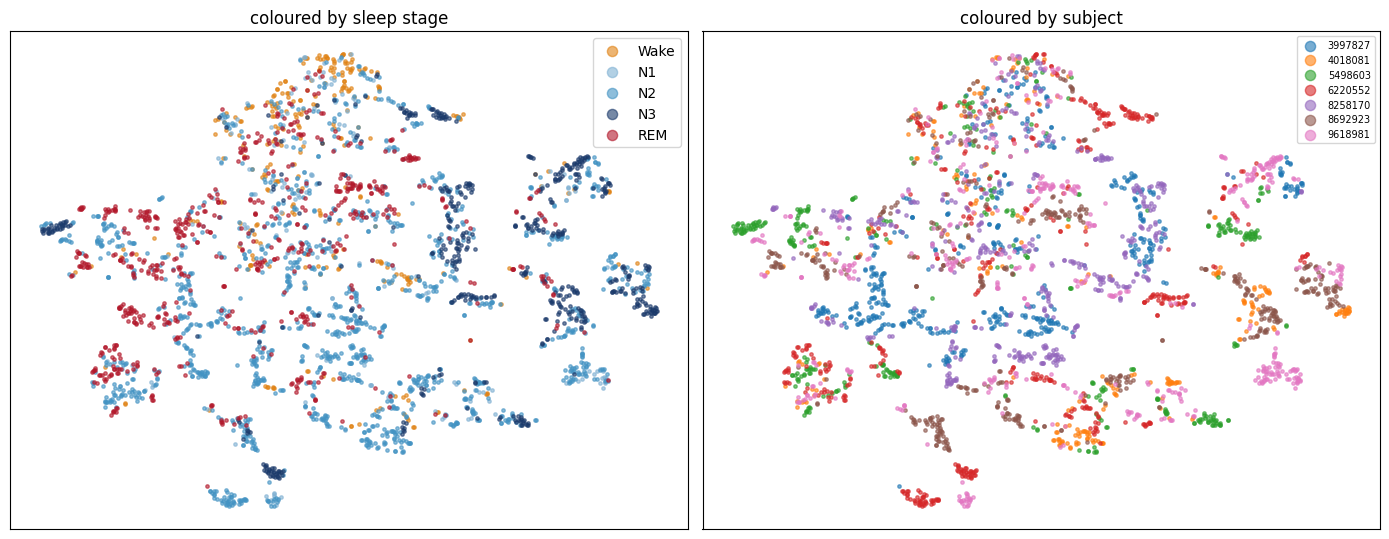

In [41]:
from sklearn.manifold import TSNE

E = embed_all(model, test_data)
Z = np.concatenate([E[s] for s in test_data]); Y = np.concatenate([test_data[s]["y"] for s in test_data])
S = np.concatenate([[s] * len(test_data[s]["y"]) for s in test_data])
sel = np.random.default_rng(SEED).choice(len(Z), size=min(3000, len(Z)), replace=False)
xy = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(Z[sel])

colors = ["#e08214", "#80b1d3", "#4393c3", "#1b3a6b", "#b2182b"]
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for c, name in enumerate(LABELS):
    m = Y[sel] == c
    ax[0].scatter(xy[m, 0], xy[m, 1], s=6, alpha=0.6, c=colors[c], label=name)
ax[0].legend(markerscale=3); ax[0].set_title("coloured by sleep stage")
for s in sorted(set(S)):
    m = S[sel] == s
    ax[1].scatter(xy[m, 0], xy[m, 1], s=6, alpha=0.6, label=s)
ax[1].legend(markerscale=3, fontsize=7); ax[1].set_title("coloured by subject")
for a in ax: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

## 10. Save outputs & verify the frozen data was not modified

Everything is saved in `ColabData/oneshot_outputs/`, never in `frozen/`.

In [42]:
torch.save(model.state_dict(), OUT_DIR / "protonet_encoder.pt")
all_res.to_csv(OUT_DIR / "oneshot_test_episodes.csv", index=False)
summary.to_csv(OUT_DIR / "oneshot_test_summary.csv")
cfg_tab.to_csv(OUT_DIR / "oneshot_validation_grid.csv")
ablation.to_csv(OUT_DIR / "oneshot_guard_ablation_validation.csv")
pd.concat({f"K={k}": pd.concat({"original": class_table(0.0, 1, k), "selected": class_table(SEL_BETA, SEL_WIN, k)}, axis=1) for k in KS}).to_csv(OUT_DIR / "oneshot_test_per_class.csv")
with open(OUT_DIR / "run_config.json", "w") as fh:
    json.dump({"seed": SEED, "features": feature_cols, "labels": LABELS,
               "val_subjects": sorted(S_val), "test_subjects": sorted(S_test),
               "scaler_mean": scaler.mean_.tolist(), "scaler_scale": scaler.scale_.tolist(),
               "guard_epochs": GUARD_EPOCHS, "n_steps": N_STEPS, "train_k_choices": TRAIN_K_CHOICES,
               "n_query": N_QUERY, "embedding_dim": EMB_DIM, "eval_ks": KS,
               "class_prior": class_prior.tolist(), "grid_betas": BETAS, "grid_windows": WINS, "macro_f1_tolerance": MF1_TOLERANCE,
               "selected_on_validation": {"beta": SEL_BETA, "window": SEL_WIN}, "best_step": best["step"]}, fh, indent=2)
print("Saved to", OUT_DIR, "->", sorted(p.name for p in OUT_DIR.iterdir()))
after = {f: sha256(FROZEN_DIR / f) for f in REQUIRED}
assert after == FROZEN_HASHES, "Frozen data changed!"
print("Frozen dataset verified: SHA-256 identical to the fingerprint taken at the start.")

Saved to /content/drive/MyDrive/Colab Notebooks/ColabData/oneshot_outputs -> ['oneshot_guard_ablation_validation.csv', 'oneshot_test_episodes.csv', 'oneshot_test_per_class.csv', 'oneshot_test_summary.csv', 'oneshot_validation_grid.csv', 'protonet_encoder.pt', 'run_config.json']
Frozen dataset verified: SHA-256 identical to the fingerprint taken at the start.


## 11. Summary & talking points for the presentation

**What was done.** A Prototypical Network was trained with simulated one-shot episodes on the meta-train subjects, a checkpoint was chosen on the 5 validation subjects, and two optional post-processing steps — a **class prior (β)** and **temporal smoothing** — were tuned **on the validation subjects only** under a macro-F1 constraint. The 7 test subjects were used once, to compare the **original ProtoNet** with the **selected configuration**.

**How to read the results.**
* Section 7b shows how the choice was made (validation grid, constraint, per-subject consistency). If the selected setting is `β = 0, window = 1`, validation found nothing that beat the pure rule — report that honestly.
* Section 8 reports accuracy, balanced accuracy and macro-F1 (mean ± std across subjects) for every K, and per-class precision / recall for original vs selected. The verdict lines claim an improvement only if it is consistent (better in at least 5 of 7 test subjects).
* A higher accuracy obtained through a class prior usually comes with *lower recall for the rare stages* (N1, Wake). Compare the per-class tables before claiming the selected setting is "better".
* One-shot reaching 60 % accuracy is not a realistic target: with a single labelled epoch per stage the models are far below fully supervised ones (~52–57 % on these 12 features).

**Limitations.**
1. Only 5 validation subjects drive the selection and 7 test subjects the final claim: differences of a point or two are within noise.
2. Support epochs are random; a real expert would pick clear examples, which would likely help.
3. Smoothing uses epochs before and after, so it is an offline step; support epochs are excluded from the averaging but the other epochs of the night are used unlabelled (transductive setting).
4. `*_subj_z` and `night_position` use whole-night information in the frozen features.
5. Little hyper-parameter tuning was done for the ProtoNet itself.

**Key vocabulary:** *N-way K-shot*, *support / query*, *episode*, *prototype*, *meta-train / meta-validation / meta-test*, *temporal guard*, *class prior*, *macro-F1*, *balanced accuracy*.